A/B test: Cookie Cats mobile game. Gate at level 30 (control) vs level 40 (test).

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, chisquare, norm


In [2]:
PATH = "/content/drive/MyDrive/Projects/A B/cookie_cats.csv"
ALPHA = 0.05
CONTROL, TEST = "gate_30", "gate_40"

H0: 7-day retention is the same for gate_30 and gate_40.

H1: 7-day retention is different.


In [3]:
print("Hypothesis written down. Primary metric: retention_7, alpha =", ALPHA)

Hypothesis written down. Primary metric: retention_7, alpha = 0.05


In [4]:
df = pd.read_csv(PATH)
print(df.head())
print("Rows:", len(df))
print("Duplicate userids:", df["userid"].duplicated().sum())
print("Nulls per column:\n", df.isna().sum())

   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
Rows: 90189
Duplicate userids: 0
Nulls per column:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


In [5]:
# retention columns are True/False in the file: turn them into 1/0
for c in ["retention_1", "retention_7"]:
    df[c] = df[c].astype(str).str.lower().isin(["true", "1"]).astype(int)


In [6]:
# remove one absurd outlier in rounds played if there is one (does not affect retention)
top2 = df["sum_gamerounds"].nlargest(2).values
if top2[0] > 10 * top2[1]:
    df = df[df["sum_gamerounds"] < top2[0]].copy()
    print("Removed 1 extreme outlier with", top2[0], "rounds played")


Removed 1 extreme outlier with 49854 rounds played


In [8]:
#Check the groups are balanced
counts = df["version"].value_counts()
print(counts)
chi_srm, p_srm = chisquare(counts.values)
print(f"Sample-ratio check p-value: {p_srm:.4f}")
print("Note: If this is below 0.001, investigate how users were assigned before trusting the test.")


version
gate_40    45489
gate_30    44699
Name: count, dtype: int64
Sample-ratio check p-value: 0.0085
Note: If this is below 0.001, investigate how users were assigned before trusting the test.


In [9]:
#group metrics with sql
con = sqlite3.connect(":memory:")
df.to_sql("players", con, index=False)
query = """
SELECT version,
       COUNT(*)                           AS users,
       SUM(retention_7)                   AS retained_7,
       ROUND(100.0 * AVG(retention_7), 2) AS retention_7_pct,
       ROUND(100.0 * AVG(retention_1), 2) AS retention_1_pct
FROM players
GROUP BY version
ORDER BY version;
"""
print(pd.read_sql(query, con).to_string(index=False))

version  users  retained_7  retention_7_pct  retention_1_pct
gate_30  44699        8501            19.02            44.82
gate_40  45489        8279            18.20            44.23


The hypothesis test

In [10]:
def two_prop_test(x1, n1, x0, n0):
    """x = number retained, n = group size. Group 1 = test, group 0 = control."""
    p1, p0 = x1 / n1, x0 / n0
    diff = p1 - p0
    p_pool = (x1 + x0) / (n1 + n0)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n0))   # standard error if H0 is true
    z = diff / se_pool
    p_value = 2 * (1 - norm.cdf(abs(z)))                            # two-sided
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)           # standard error for the CI
    return {"p_test": p1, "p_ctrl": p0, "diff": diff,
            "rel_lift": diff / p0 if p0 else np.nan, "z": z, "p_value": p_value,
            "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se}

def run_metric(data, metric):
    t = data[data["version"] == TEST][metric]
    c = data[data["version"] == CONTROL][metric]
    return two_prop_test(t.sum(), len(t), c.sum(), len(c))

res7 = run_metric(df, "retention_7")
print(f"7-day retention: control {res7['p_ctrl']*100:.2f}%  test {res7['p_test']*100:.2f}%")
print(f"Difference: {res7['diff']*100:+.2f} pp  (relative {res7['rel_lift']*100:+.2f}%)")
print(f"95% CI: {res7['ci_low']*100:.2f} to {res7['ci_high']*100:.2f} pp")
print(f"z = {res7['z']:.3f}, p-value = {res7['p_value']:.4f}")
print("Significant at", ALPHA, "?", "YES" if res7["p_value"] < ALPHA else "NO")


7-day retention: control 19.02%  test 18.20%
Difference: -0.82 pp  (relative -4.30%)
95% CI: -1.33 to -0.31 pp
z = -3.157, p-value = 0.0016
Significant at 0.05 ? YES


In [11]:
chi2, p_chi, _, _ = chi2_contingency(pd.crosstab(df["version"], df["retention_7"]), correction=False)
print(f"Chi-square p-value: {p_chi:.4f}  (should equal the z-test p-value above)")


Chi-square p-value: 0.0016  (should equal the z-test p-value above)


In [12]:
#Simulation check of the confidence interval
rng = np.random.default_rng(42)
t = df[df["version"] == TEST]["retention_7"]
c = df[df["version"] == CONTROL]["retention_7"]
sim = rng.binomial(len(t), t.mean(), 10000) / len(t) - rng.binomial(len(c), c.mean(), 10000) / len(c)
lo, hi = np.percentile(sim, [2.5, 97.5])
print(f"Simulated 95% interval: {lo*100:.2f} to {hi*100:.2f} pp (should be close to the formula CI)")

Simulated 95% interval: -1.33 to -0.32 pp (should be close to the formula CI)


In [13]:
#Secondary metric (1-day retention)
res1 = run_metric(df, "retention_1")
print(f"1-day retention difference: {res1['diff']*100:+.2f} pp, p-value = {res1['p_value']:.4f}")

1-day retention difference: -0.59 pp, p-value = 0.0739


In [14]:
#Segment by rounds played (exploratory only)
df["segment"] = pd.cut(df["sum_gamerounds"], [-1, 29, 99, np.inf],
                       labels=["<30 rounds", "30-99 rounds", "100+ rounds"])
rows = []
for seg, g in df.groupby("segment", observed=True):
    r = run_metric(g, "retention_7")
    r.update({"segment": seg, "n": len(g)})
    rows.append(r)
seg_df = pd.DataFrame(rows)
alpha_adj = ALPHA / len(seg_df)                      # Bonferroni correction for 3 looks
seg_df["significant_after_correction"] = seg_df["p_value"] < alpha_adj
print(seg_df[["segment", "n", "diff", "p_value", "significant_after_correction"]].round(4).to_string(index=False))
print(f"Adjusted alpha for segments: {alpha_adj:.4f}")

     segment     n    diff  p_value  significant_after_correction
  <30 rounds 56920 -0.0033   0.0490                         False
30-99 rounds 20753 -0.0217   0.0004                          True
 100+ rounds 12515 -0.0011   0.8955                         False
Adjusted alpha for segments: 0.0167


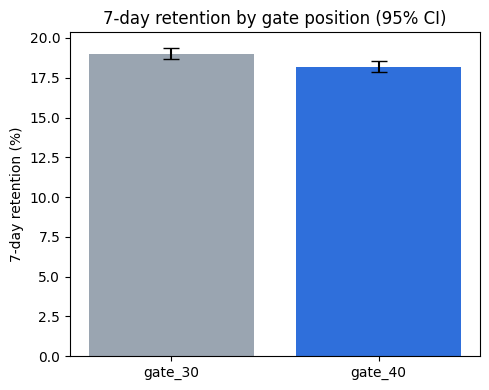

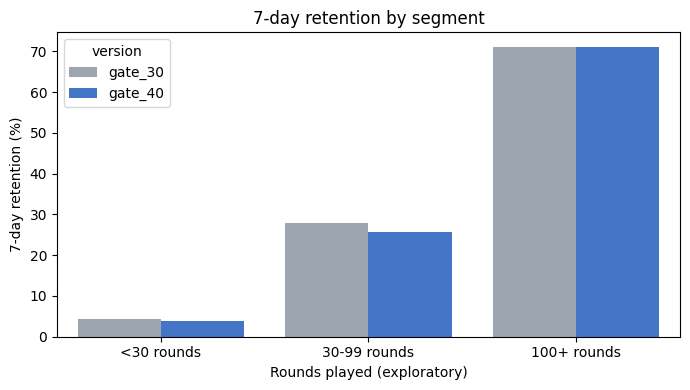

In [15]:
#Charts
fig, ax = plt.subplots(figsize=(5, 4))
vals, errs = [], []
for g in [CONTROL, TEST]:
    s = df[df["version"] == g]["retention_7"]
    p = s.mean()
    vals.append(p * 100)
    errs.append(1.96 * np.sqrt(p * (1 - p) / len(s)) * 100)
ax.bar([CONTROL, TEST], vals, yerr=errs, capsize=6, color=["#9aa5b1", "#2f6fdb"])
ax.set_ylabel("7-day retention (%)")
ax.set_title("7-day retention by gate position (95% CI)")
plt.tight_layout()
plt.savefig("retention7_by_version.png", dpi=150)
plt.show()

plot_df = (df.groupby(["segment", "version"], observed=True)["retention_7"]
             .mean().mul(100).reset_index())
plt.figure(figsize=(7, 4))
sns.barplot(data=plot_df, x="segment", y="retention_7", hue="version",
            palette={CONTROL: "#9aa5b1", TEST: "#2f6fdb"})
plt.ylabel("7-day retention (%)")
plt.xlabel("Rounds played (exploratory)")
plt.title("7-day retention by segment")
plt.tight_layout()
plt.savefig("retention7_by_segment.png", dpi=150)
plt.show()

In [16]:
#Summary
print("=" * 60)
print(f"[N]         = {len(df):,} players")
print(f"[X] pp      = {res7['diff']*100:+.2f} pp (gate_40 minus gate_30)")
print(f"[low, high] = {res7['ci_low']*100:.2f}, {res7['ci_high']*100:.2f}")
print(f"[p-value]   = {res7['p_value']:.4f}")
print("=" * 60)
if res7["p_value"] < ALPHA:
    print("Result: statistically significant. Now ask if the size of the change matters in practice.")
else:
    print("Result: NOT significant. Honest recommendation: no evidence the gate move changes 7-day retention.")

[N]         = 90,188 players
[X] pp      = -0.82 pp (gate_40 minus gate_30)
[low, high] = -1.33, -0.31
[p-value]   = 0.0016
Result: statistically significant. Now ask if the size of the change matters in practice.
